# Task 3 — Evaluation, Optimisation and Explainability

| | |
|---|---|
| **Module** | 7006SCN Machine Learning and Big Data |
| **Student** | Manish Saini — SID 17142113 — sainim10@coventry.ac.uk |
| **Pool reference** | 112 |
| **Dataset** | NOAA GHCN-Daily, US stations (`CatLikeIceCream/temperature`, `climate.csv`), prepared in Task 1 |
| **Problem** | Regression: predict `label_TMAX_next`, the next-day maximum temperature (°C) at the same station |
| **Models** | The four models tuned and saved in Task 2 (`results/task2.json`, `models/task2/`) |


## 0 Setup
### 0.1 Environment, paths and run settings
These are the same Windows settings as Tasks 1 and 2: Spark uses the Hadoop helper files in `E:\hadoop`, and its temporary files go to `E:` because `C:` is almost full.

The notebook finds the repository root by looking upwards for `results/task1.json` (with the handoff block) and `results/task2.json`.

In [6]:
# ==============================================================================
# 0.1  Environment, paths and run settings
# REF: Task 2 notebook, cell 0.1 - the same Windows/Hadoop settings and repository-root search are reused
## AI: settings block and  written with AI assistance
# ==============================================================================
import os, sys, json, time, math, platform, tempfile, statistics, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore", category=UserWarning)

# ---- Windows only: Hadoop helper files and a temp folder that is not on the full C: drive ----
if os.name == "nt":
    os.environ["HADOOP_HOME"] = os.environ.get("HADOOP_HOME", r"E:\hadoop")
    os.environ["PATH"] = os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]
    LOCAL_DIR = os.environ.get("CW_LOCAL_DIR", "E:/spark-tmp")
    os.environ["TEMP"] = os.environ["TMP"] = LOCAL_DIR
else:
    LOCAL_DIR = os.environ.get("CW_LOCAL_DIR", os.path.join(tempfile.gettempdir(), "spark-tmp"))
os.makedirs(LOCAL_DIR, exist_ok=True)


def find_project_root():
    """The repository root: the nearest folder (this one or above) whose results/task1.json has Task 1's
    'handoff' block, whose handoff data exists, and which also holds Task 2's results/task2.json."""
    tried = []
    for candidate in (Path("."), Path(".."), Path("../..")):
        f = candidate / "results" / "task1.json"
        if f.exists():
            tried.append(f.resolve().as_posix())
            h = json.loads(f.read_text()).get("handoff")
            if h and (candidate / h["train_path"]).exists() and (candidate / "results" / "task2.json").exists():
                return candidate
    raise FileNotFoundError(f"No repository root with results/task1.json (handoff) and results/task2.json was "
                            f"found (checked: {tried}). Run Tasks 1 and 2 first, then open this notebook from "
                            "the notebooks/ folder of the repository.")


ROOT = find_project_root()            # relative path to the repository root ("..", when run from notebooks/)

# ---- run settings ----
QUICK_TEST     = False   # True = small samples for a code check only; outputs go to task3/quick_test/
SEED           = 42
REPEATS        = 1 if QUICK_TEST else 3   # each light before/after workload is timed 3 times; the median is used
REPEATS_HEAVY  = 1 if QUICK_TEST else 2   # the 2.5-million-row scoring workload is timed twice per setting
TASKS_PER_CORE = 2                         # Spark tuning guide: 2-3 tasks per CPU core
TUNE_PCT       = 2 if QUICK_TEST else 10   # the same 10% tuning sample as Task 2
CV_FOLDS       = 3                         # the same three year-block folds as Task 2
NOTEBOOK       = "notebooks/task3.ipynb"

# ---- output folders (relative to the repository root) ----
OUT_DIR = ROOT / "task3" / ("quick_test" if QUICK_TEST else "")
RES_DIR = OUT_DIR / "results"
FIG_DIR = OUT_DIR / "figures"
for d in (RES_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)


def spark_path(p):
    """Spark gets an absolute path; everything printed or saved stays relative to the repository root."""
    return Path(p).resolve().as_posix()


def rel(p):
    return Path(os.path.relpath(Path(p).resolve(), ROOT.resolve())).as_posix()


def show(df, title=None):
    """Display a pandas table with a title (HTML in Jupyter, plain text elsewhere)."""
    if title:
        print(title)
    try:
        from IPython.display import display
        display(df)
    except Exception:
        print(df.to_string(index=False))


print(f"repository root : {ROOT.resolve()}")
print(f"inputs          : results/task1.json (handoff), results/task2.json (models)")
print(f"outputs         : {rel(RES_DIR)}/  {rel(FIG_DIR)}/  results/task3.json")
print(f"Spark temp dir  : {LOCAL_DIR}")
print(f"mode            : {'QUICK TEST - small samples, not for the report' if QUICK_TEST else 'full run'}")

repository root : C:\Users\Manish Saini\sainim10_17142113
inputs          : results/task1.json (handoff), results/task2.json (models)
outputs         : task3/results/  task3/figures/  results/task3.json
Spark temp dir  : E:/spark-tmp
mode            : full run


### 0.2 SparkSession and executor configuration
This is **the Task 2 configuration**, unchanged, so that every "before" time in section 3.1 is measured on the setup that Task 2 really used:

- `local[*]`: one Java process that is both driver and executor, using every laptop core;
- a 4 GB driver (6 GB crashed the JVM in Task 1);
- 32 shuffle partitions, adaptive query execution (AQE) on.

In [7]:
# ==============================================================================
# 0.2  SparkSession and executor configuration
# REF: Task 2 notebook cell 0.2 (same settings); Task 1 notebook section 2 (SparkSession)
#      Changed: app name, and the Spark UI keeps more jobs/stages so this run's timeline can be read back.
# ==============================================================================
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark import SparkContext, StorageLevel
from pyspark.sql import SparkSession, functions as F

# clear any dead Spark/Java session left over from a crash (same block as Tasks 1 and 2)
try:
    SparkSession.getActiveSession().stop()
except Exception:
    pass
SparkContext._active_spark_context = None; SparkContext._gateway = None; SparkContext._jvm = None
SparkSession._instantiatedSession = None; SparkSession._activeSession = None

DRIVER_MEMORY      = os.environ.get("CW_DRIVER_MEMORY", "4g")
SHUFFLE_PARTITIONS = int(os.environ.get("CW_SHUFFLE_PARTITIONS", "32"))

builder = (SparkSession.builder
           .appName("7006SCN-Task3-Optimisation")
           .master("local[*]")                                         # EXPLAIN: one JVM using every CPU core
           .config("spark.driver.memory", DRIVER_MEMORY)
           .config("spark.local.dir", LOCAL_DIR)                       # EXPLAIN: shuffle and spill files
           .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTITIONS))
           .config("spark.sql.adaptive.enabled", "true")
           .config("spark.sql.ansi.enabled", "true")
           .config("spark.ui.retainedJobs", "5000")                    # EXPLAIN: the UI keeps every job of this run
           .config("spark.ui.retainedStages", "5000")
           .config("spark.ui.showConsoleProgress", "false"))
if os.name == "nt":                                                    # EXPLAIN: lets the JVM load hadoop.dll
    hh = os.environ["HADOOP_HOME"].replace("\\", "/")
    builder = builder.config("spark.driver.extraJavaOptions",
                             f"-Djava.library.path={hh}/bin -Dhadoop.home.dir={hh}")
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
sc.setCheckpointDir(Path(LOCAL_DIR, "checkpoints").as_posix())

N_CORES = sc.defaultParallelism
EXECUTOR_CONFIG = {
    "spark_version": spark.version,
    "master": sc.master,
    "cores (default parallelism)": N_CORES,
    "driver_memory": spark.conf.get("spark.driver.memory"),
    "executor": "local mode - the driver JVM is also the executor",
    "shuffle_partitions": spark.conf.get("spark.sql.shuffle.partitions"),
    "adaptive_query_execution": spark.conf.get("spark.sql.adaptive.enabled"),
    "os": platform.platform(),
    "python": platform.python_version(),
}
for k, v in EXECUTOR_CONFIG.items():
    print(f"{k:<28}: {v}")
print(f"\nSpark UI: {sc.uiWebUrl}   <- open this in a browser now and keep it open (see section 3.1.7)")

spark_version               : 4.2.0
master                      : local[*]
cores (default parallelism) : 12
driver_memory               : 4g
executor                    : local mode - the driver JVM is also the executor
shuffle_partitions          : 32
adaptive_query_execution    : true
os                          : Windows-11-10.0.26300-SP0
python                      : 3.14.6

Spark UI: http://10.1.110.175:4040   <- open this in a browser now and keep it open (see section 3.1.7)


## 3.0 Inputs from Task 1 and Task 2
Nothing is retrained here. The notebook loads:

- the training (1970–2015) and test (2016–2023) Parquet files that Task 1 handed over;
- the four fitted pipelines that Task 2 saved, and the model Task 2 recommended.

It also records **how Spark splits the input files into partitions**. That decides how many tasks each stage gets, and therefore what the stage timeline will look like.

In [8]:
# ==============================================================================
# 3.0  Load the Task 1 handoff data and the Task 2 models
# REF: Task 2 notebook cells 1.1 and 1.6 (handoff loading, Task 1 stages rebuilt unfitted);
#      Day05_LiveCoding_Colab > Block 4 (cell-11): PipelineModel.load(path) and reuse without refitting
## AI: input-layout table written with AI assistance
# ==============================================================================
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator

task1 = json.loads((ROOT / "results" / "task1.json").read_text())
task2 = json.loads((ROOT / "results" / "task2.json").read_text())
H = task1["handoff"]
TARGET = H["target_col"]                                            # label_TMAX_next
assert task2.get("models"), "results/task2.json has no 'models' block - run notebooks/task2.ipynb first"
MODEL_PATHS = {n: ROOT / m["model_path"] for n, m in task2["models"].items()}
missing = [n for n, p in MODEL_PATHS.items() if not (p / "metadata").exists()]
assert not missing, f"Task 2 models not found on disk: {missing} - re-run notebooks/task2.ipynb"
RECOMMENDED = task2["recommendation"]["recommended_model"]

train_raw  = spark.read.parquet(spark_path(ROOT / H["train_path"]))
test_raw   = spark.read.parquet(spark_path(ROOT / H["test_path"]))
t1_prep    = PipelineModel.load(spark_path(ROOT / H["preprocessing_model_path"]))
best_model = PipelineModel.load(spark_path(MODEL_PATHS[RECOMMENDED]))
FEATURES_COL = t1_prep.stages[-1].getOutputCol()                    # 'features'

from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
imp_m, idx_m, ohe_m, va_t1, scaler_m = t1_prep.stages
MODEL_COLS = ["ID", "date", "YEAR"] + list(idx_m.getInputCols()) + [TARGET] + list(imp_m.getInputCols())


def make_preprocessing_stages():
    """New, UNFITTED copies of Task 1's five stages with Task 1's exact settings (same as Task 2 cell 1.6)."""
    return [
        Imputer(inputCols=imp_m.getInputCols(), outputCols=imp_m.getOutputCols(), strategy=imp_m.getStrategy()),
        StringIndexer(inputCols=idx_m.getInputCols(), outputCols=idx_m.getOutputCols(),
                      handleInvalid=idx_m.getHandleInvalid(), stringOrderType=idx_m.getStringOrderType()),
        OneHotEncoder(inputCols=ohe_m.getInputCols(), outputCols=ohe_m.getOutputCols(),
                      dropLast=ohe_m.getDropLast(), handleInvalid=ohe_m.getHandleInvalid()),
        VectorAssembler(inputCols=va_t1.getInputCols(), outputCol=va_t1.getOutputCol(),
                        handleInvalid=va_t1.getHandleInvalid()),
        StandardScaler(inputCol=scaler_m.getInputCol(), outputCol=scaler_m.getOutputCol(),
                       withMean=scaler_m.getWithMean(), withStd=scaler_m.getWithStd()),
    ]



def input_layout(split, df, folder):
    """Parquet files on disk -> Spark input partitions -> rows per partition."""
    sizes = sorted((f.stat().st_size for f in Path(folder).glob("*.parquet")), reverse=True)
    per_part = (df.groupBy(F.spark_partition_id().alias("partition")).count().toPandas()["count"])
    return {"Split": split, "Rows": int(per_part.sum()), "Parquet files": len(sizes),
            "File size min-max (MB)": f"{sizes[-1] / 1e6:.2f}-{sizes[0] / 1e6:.2f}",
            "Spark input partitions": df.rdd.getNumPartitions(), "Cores": N_CORES,
            "Rows per partition (min / median / max)": f"{per_part.min():,} / {int(per_part.median()):,} / {per_part.max():,}",
            "Largest / median partition": round(per_part.max() / per_part.median(), 2)}


INPUT_LAYOUT = pd.DataFrame([input_layout("train", train_raw, ROOT / H["train_path"]),
                             input_layout("test", test_raw, ROOT / H["test_path"])])
N_TRAIN, N_TEST = (int(x) for x in INPUT_LAYOUT["Rows"])
assert (N_TRAIN, N_TEST) == (H["train_rows"], H["test_rows"]), "row counts differ from results/task1.json"
show(INPUT_LAYOUT, "Table 3.0  How Spark reads the Task 1 handoff files")
INPUT_LAYOUT.to_csv(RES_DIR / "task3_input_layout.csv", index=False)

print(f"models loaded from results/task2.json : {list(MODEL_PATHS)}")
print(f"recommended in Task 2                 : {RECOMMENDED} "
      f"(test RMSE {task2['models'][RECOMMENDED]['test_metrics']['RMSE']:.3f} deg C)")

Table 3.0  How Spark reads the Task 1 handoff files


,Split,Rows,Parquet files,File size min-max (MB),Spark input partitions,Cores,Rows per partition (min / median / max),Largest / median partition
0,train,2555512,23,0.78-2.42,11,12,"145,462 / 237,354 / 331,084",1.39
1,test,433788,12,0.22-0.81,12,12,"11,168 / 37,868 / 53,961",1.42


models loaded from results/task2.json : ['LinearRegression', 'RandomForestRegressor', 'FMRegressor', 'GBTRegressor']
recommended in Task 2                 : GBTRegressor (test RMSE 3.853 deg C)


## 3.1 Spark UI interpretation and optimisation
### 3.1.1 How the timings are measured
The method is the same for every change:

1. **Read before changing.** The workload is run once with the Task 2 settings. 
2. **One change at a time.** Each change is compared against the Task 2 settings, never against another change.

| Column | Meaning |
|---|---|
| Duration (s) | Stage start to stage end, as on the Stages page |
| Task time (s) | Total time all tasks spent working |
| Median / max task (s) | From the stage's *Summary Metrics*; max ÷ median > 1.5 means one task holds the stage up (**skew**) |
| Rows per task | Smallest and largest number of rows a task read |
| Shuffle write / read (MB) | Data moved between stages (**shuffle**) |
| Spill (MB) | Data pushed out of memory to disk while a task ran (**spill**) |
| Core use (%) | Task time ÷ (wall time × cores): how busy the cores were |

In [9]:
# ==============================================================================
# 3.1.1  Spark UI helpers: job groups, REST API, stage and job tables, fair timing
# REF: Week 5 lecture "Performance Tuning & Debugging" (reading the Jobs/Stages pages);
#      Spark docs "Monitoring and Instrumentation" (REST API /applications/[app-id]/jobs, /stages,
#      /stages/[stage-id]/[attempt-id]/taskSummary, /taskList, /storage/rdd, /executors)
## AI: REST-API helpers, stage/job tables and the alternating timing harness written with AI assistance
# ==============================================================================
import urllib.request
from datetime import datetime

_opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))    # EXPLAIN: localhost never via a proxy


def ui_api(path, timeout=30):
    """GET /api/v1/applications/<this app>/<path> from the live Spark UI; None if it cannot be reached."""
    port = (sc.uiWebUrl or ":4040").rsplit(":", 1)[-1]
    for base in dict.fromkeys([sc.uiWebUrl, f"http://localhost:{port}", f"http://127.0.0.1:{port}"]):
        if not base:
            continue
        try:
            with _opener.open(f"{base}/api/v1/applications/{sc.applicationId}/{path}", timeout=timeout) as r:
                return json.loads(r.read().decode("utf-8"))
        except Exception:
            continue
    return None


def _ts(s):
    return datetime.strptime(s.replace("GMT", "+0000"), "%Y-%m-%dT%H:%M:%S.%f%z")


def run_timed(group, description, fn):
    """Run fn() inside a named Spark job group and return its wall-clock time in seconds."""
    sc.setJobGroup(group, description)
    try:
        t0 = time.perf_counter()
        fn()
        return time.perf_counter() - t0
    finally:
        sc.setLocalProperty("spark.jobGroup.id", None)
        sc.setLocalProperty("spark.job.description", None)


def group_jobs(group, wait_s=20):
    """Finished jobs of one job group (waits briefly until the UI has recorded the last job)."""
    deadline = time.time() + wait_s
    while True:
        jobs = [j for j in (ui_api("jobs") or []) if j.get("jobGroup") == group]
        if (jobs and all(j.get("status") != "RUNNING" for j in jobs)) or time.time() > deadline:
            return sorted(jobs, key=lambda j: j["jobId"])
        time.sleep(0.5)


def _quantiles(summary, *keys):
    v = summary
    for k in keys:
        v = (v or {}).get(k)
    return v if isinstance(v, list) and len(v) == 3 else [0, 0, 0]


def group_stages(group, detail_top=4):
    """One row per stage that ran in the job group. Task-level summaries (median/max task, rows per task)
    are fetched for the longest `detail_top` stages, which is where a bottleneck would show."""
    jobs = group_jobs(group)
    job_of = {sid: j["jobId"] for j in jobs for sid in j.get("stageIds", [])}
    stages = {}
    for s in (ui_api("stages?status=complete") or []):
        if s["stageId"] in job_of:
            stages[(s["stageId"], s["attemptId"])] = s
    rows = []
    for (sid, att), s in sorted(stages.items()):
        rows.append({"Job": job_of[sid], "Stage": sid, "Attempt": att,
                     "Action": s.get("name", "").split(" at ")[0],
                     "Tasks": s["numTasks"],
                     "Duration (s)": round((_ts(s["completionTime"]) - _ts(s["submissionTime"])).total_seconds(), 2),
                     "Task time (s)": round(s["executorRunTime"] / 1000, 2),
                     "Input rows": s.get("inputRecords", 0),
                     "Shuffle write (MB)": round(s.get("shuffleWriteBytes", 0) / 1e6, 2),
                     "Shuffle read (MB)": round(s.get("shuffleReadBytes", 0) / 1e6, 2),
                     "Spill (MB)": round((s.get("memoryBytesSpilled", 0) + s.get("diskBytesSpilled", 0)) / 1e6, 2),
                     "GC (s)": round(s.get("jvmGcTime", 0) / 1000, 2)})
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    df["Median task (s)"] = np.nan; df["Max task (s)"] = np.nan; df["Max / median"] = np.nan
    df["Rows per task (min-max)"] = ""
    for i in df.nlargest(detail_top, "Duration (s)").index:
        q = ui_api(f"stages/{df.at[i, 'Stage']}/{df.at[i, 'Attempt']}/taskSummary?quantiles=0.0,0.5,1.0") or {}
        run = _quantiles(q, "executorRunTime")
        recs = _quantiles(q, "inputMetrics", "recordsRead")
        if not any(recs):
            recs = _quantiles(q, "shuffleReadMetrics", "readRecords")
        df.at[i, "Median task (s)"] = round(run[1] / 1000, 3)
        df.at[i, "Max task (s)"] = round(run[2] / 1000, 3)
        df.at[i, "Max / median"] = round(run[2] / run[1], 2) if run[1] else np.nan
        df.at[i, "Rows per task (min-max)"] = f"{int(recs[0]):,}-{int(recs[2]):,}" if any(recs) else ""
    return df


def group_jobs_table(group):
    rows = []
    for j in group_jobs(group):
        dur = (_ts(j["completionTime"]) - _ts(j["submissionTime"])).total_seconds()
        rows.append({"Job": j["jobId"], "Action": j.get("name", "").split(" at ")[0],
                     "Duration (s)": round(dur, 2), "Stages run": j.get("numCompletedStages", 0),
                     "Stages skipped": j.get("numSkippedStages", 0), "Tasks": j.get("numCompletedTasks", 0)})
    return pd.DataFrame(rows)


def core_use(stages_df, wall_s):
    """Share of the available core-seconds that tasks actually used."""
    if stages_df.empty or not wall_s:
        return float("nan")
    return round(100 * stages_df["Task time (s)"].sum() / (wall_s * N_CORES), 1)


def compare(name, before_fn, after_fn, repeats, after_first=False):
    """Time before_fn and after_fn in turns (B, A, B, A, ...); each run gets its own job group."""
    runs, groups = {"before": [], "after": []}, {"before": [], "after": []}
    order = ("after", "before") if after_first else ("before", "after")
    for i in range(1, repeats + 1):
        for which in order:
            g = f"t3_{name}_{which}_{i}"
            runs[which].append(run_timed(g, f"T3.1 {name}: {which.upper()} run {i}",
                                         before_fn if which == "before" else after_fn))
            groups[which].append(g)
            print(f"  {name:<12} {which:<6} run {i}: {runs[which][-1]:6.2f} s", flush=True)
    return runs, groups


UI_REACHABLE = ui_api("environment") is not None
ex = (ui_api("executors") or [{}])[0]
RESOURCES = {"cores": ex.get("totalCores", N_CORES),
             "storage_memory_mb": round(ex.get("maxMemory", 0) / 2**20),
             "driver_memory": spark.conf.get("spark.driver.memory")}
print(f"Spark UI REST API reachable: {UI_REACHABLE}  ({sc.uiWebUrl}/api/v1/applications/{sc.applicationId})")
print(f"Executors page: {RESOURCES['cores']} cores, {RESOURCES['storage_memory_mb']:,} MB storage memory "
      f"(part of the {RESOURCES['driver_memory']} driver heap that can hold cached data)")
if not UI_REACHABLE:
    print("WARNING: the Spark UI could not be read - timings still run, but the stage tables will be empty.")

Spark UI REST API reachable: True  (http://10.1.110.175:4040/api/v1/applications/local-1792588200755)
Executors page: 12 cores, 2,278 MB storage memory (part of the 4g driver heap that can hold cached data)


### 3.1.2 Baseline: what the stage timeline shows

Here it runs exactly as Task 2 would have run it: nothing is cached, and the input keeps its original partitions. The two tables below are the **Jobs** and **Stages** pages of the Spark UI for this one run.

In [10]:
# ==============================================================================
# 3.1.2  Baseline evaluation job (Task 2 settings) and its stage timeline
# REF: Day06_Regression_LiveCoding_Solutions_Colab > cell-9 [Day 6]: RegressionEvaluator(metricName=...)
#      Changed: the same metrics as Table 2.3, run as one job group so the Spark UI timeline can be read
## AI: evaluation workload and diagnosis summary written with AI assistance
# ==============================================================================
EVAL_COLS = ["ID", "state_code", TARGET, "prediction"]               # the only columns the metrics read


def evaluation_workload(pred):
    """Five metrics + an error table by state: 6 Spark actions on the same predictions."""
    out = {m: RegressionEvaluator(labelCol=TARGET, predictionCol="prediction", metricName=m).evaluate(pred)
           for m in ("rmse", "mae", "r2", "var")}
    err = F.col(TARGET) - F.col("prediction")
    out["max_abs_error"] = pred.select(F.max(F.abs(err))).first()[0]
    out["by_state"] = (pred.groupBy("state_code")
                           .agg(F.count(F.lit(1)).alias("rows"), F.sqrt(F.avg(err * err)).alias("rmse"))
                           .toPandas())
    return out


RESULT = {}


def eval_before():
    RESULT["before"] = evaluation_workload(best_model.transform(test_raw))      # EXPLAIN: nothing cached


BASE_WALL = run_timed("t3_baseline", "T3.1 BASELINE: evaluate the recommended model, Task 2 settings", eval_before)
BASE_JOBS, BASE_STAGES = group_jobs_table("t3_baseline"), group_stages("t3_baseline", detail_top=6)
show(BASE_JOBS, f"Table 3.1a  Baseline jobs ({BASE_WALL:.1f} s wall time) - the Jobs page for this run")
show(BASE_STAGES, "Table 3.1b  Baseline stages - the Stages page for this run")
BASE_JOBS.to_csv(RES_DIR / "task3_baseline_jobs.csv", index=False)
BASE_STAGES.to_csv(RES_DIR / "task3_baseline_stages.csv", index=False)

# ---- diagnosis, read from the two tables above ----
DIAG = {"wall_s": round(BASE_WALL, 2)}
if not BASE_STAGES.empty:
    scans = BASE_STAGES[BASE_STAGES["Input rows"] >= N_TEST]                       # stages that read every test row
    top = scans.loc[scans["Duration (s)"].idxmax()] if len(scans) else None       # the slowest full scan
    DIAG.update({
        "jobs": len(BASE_JOBS), "full_scans": len(scans),
        "scan_time_s": round(scans["Duration (s)"].sum(), 2),
        "scan_share_pct": round(100 * scans["Duration (s)"].sum() / max(BASE_STAGES["Duration (s)"].sum(), 1e-9), 1),
        "scan_tasks": int(scans["Tasks"].median()) if len(scans) else None,
        "skew_max_over_median": float(top["Max / median"]) if top is not None else None,
        "skew_rows_per_task": top["Rows per task (min-max)"] if top is not None else None,
        "shuffle_write_mb": round(BASE_STAGES["Shuffle write (MB)"].sum(), 2),
        "spill_mb": round(BASE_STAGES["Spill (MB)"].sum(), 2),
        "gc_pct": round(100 * BASE_STAGES["GC (s)"].sum() / max(BASE_STAGES["Task time (s)"].sum(), 1e-9), 1),
        "core_use_pct": core_use(BASE_STAGES, BASE_WALL),
    })
    print("\nWhat the timeline shows")
    print(f"- Recomputation: {DIAG['full_scans']} of the {DIAG['jobs']} jobs re-read all {N_TEST:,} test rows and "
          f"re-ran the 5 preprocessing stages + {RECOMMENDED}; these scans are {DIAG['scan_share_pct']}% of stage time.")
    print(f"- Skew: in the slowest scan stage the longest task took {DIAG['skew_max_over_median']}x the median task "
          f"(rows per task {DIAG['skew_rows_per_task']}), with {DIAG['scan_tasks']} tasks for {N_CORES} cores.")
    print(f"- Shuffle: {DIAG['shuffle_write_mb']} MB in total - only the small error table by state is shuffled.")
    print(f"- Spill: {DIAG['spill_mb']} MB; GC: {DIAG['gc_pct']}% of task time - memory is not the bottleneck.")
    print(f"- Core use: {DIAG['core_use_pct']}% of the {N_CORES} cores over the {BASE_WALL:.1f} s run.")

Table 3.1a  Baseline jobs (70.6 s wall time) - the Jobs page for this run


,Job,Action,Duration (s),Stages run,Stages skipped,Tasks
0,50,treeAggregate,13.92,3,0,16
1,51,treeAggregate,8.83,3,0,16
2,52,treeAggregate,8.35,3,0,16
3,53,treeAggregate,7.83,3,0,16
4,54,first,9.30,1,0,12
5,55,first,0.19,1,1,1
6,56,toPandas,10.35,1,0,12
7,57,toPandas,1.07,1,1,1


Table 3.1b  Baseline stages - the Stages page for this run


,Job,Stage,Attempt,Action,Tasks,Duration (s),Task time (s),Input rows,Shuffle write (MB),Shuffle read (MB),Spill (MB),GC (s),Median task (s),Max task (s),Max / median,Rows per task (min-max)
0,50,52,0,treeAggregate,12,12.91,118.65,433788,0.01,0.00,0.0,1.62,10.275,11.220,1.09,"11,168-53,961"
1,50,53,0,treeAggregate,3,0.28,0.59,0,0.00,0.01,0.0,0.00,NaN,NaN,NaN,
2,50,54,0,treeAggregate,1,0.69,0.15,0,0.00,0.00,0.0,0.00,NaN,NaN,NaN,
3,51,55,0,treeAggregate,12,8.30,73.90,433788,0.01,0.00,0.0,0.95,6.711,7.476,1.11,"11,168-53,961"
4,51,56,0,treeAggregate,3,0.32,0.69,0,0.00,0.01,0.0,0.00,NaN,NaN,NaN,
5,51,57,0,treeAggregate,1,0.17,0.04,0,0.00,0.00,0.0,0.00,NaN,NaN,NaN,
6,52,58,0,treeAggregate,12,7.66,70.63,433788,0.01,0.00,0.0,0.91,6.481,7.532,1.16,"11,168-53,961"
7,52,59,0,treeAggregate,3,0.57,1.35,0,0.00,0.01,0.0,0.00,NaN,NaN,NaN,
8,52,60,0,treeAggregate,1,0.12,0.03,0,0.00,0.00,0.0,0.00,NaN,NaN,NaN,
9,53,61,0,treeAggregate,12,7.64,71.70,433788,0.01,0.00,0.0,0.80,6.438,7.444,1.16,"11,168-53,961"



What the timeline shows
- Recomputation: 6 of the 8 jobs re-read all 433,788 test rows and re-ran the 5 preprocessing stages + GBTRegressor; these scans are 94.0% of stage time.
- Skew: in the slowest scan stage the longest task took 1.09x the median task (rows per task 11,168-53,961), with 12 tasks for 12 cores.
- Shuffle: 0.06 MB in total - only the small error table by state is shuffled.
- Spill: 0.0 MB; GC: 1.3% of task time - memory is not the bottleneck.
- Core use: 63.2% of the 12 cores over the 70.6 s run.


### 3.1.3 Change 1 — persist the scored test set (caching / persisting)
**Diagnosis.** In Table 3.1b, almost every job begins with a stage that reads all 433,788 test rows again and runs the whole pipeline again (5 preprocessing stages + the 60-tree model). This happens because Spark is *lazy*: a DataFrame is a recipe, not stored data. Each action (`evaluate`, `first`, `toPandas`) cooks the recipe from the beginning.

**Change.** Score once, keep the result, and reuse it:

- `persist(StorageLevel.MEMORY_AND_DISK)` keeps the scored rows in memory. If the 4 GB driver runs short, blocks go to the local disk (`E:`) instead of being recomputed.
- Only the 4 columns that the metrics read are kept (`ID`, `state_code`, label, prediction), not the ~40 columns the pipeline produces. The cell measures what that saves on the *Storage* page.
- `count()` fills the cache once, and `unpersist()` frees it at the end. Both are included in the "after" time.

In [11]:
# ==============================================================================
# 3.1.3  Change 1 - persist the scored test set (MEMORY_AND_DISK, 4 columns)
# REF: Week 5 lecture "Performance Tuning & Debugging" (cache/persist, storage levels);
#      Task 2 notebook cell 1.7 (DataFrame.cache() before repeated use)
## AI: storage-size measurement and the before/after comparison written with AI assistance
# ==============================================================================
def eval_after():
    pred = best_model.transform(test_raw).select(*EVAL_COLS).persist(StorageLevel.MEMORY_AND_DISK)
    pred.count()                                                       # EXPLAIN: one scoring pass fills the cache
    RESULT["after"] = evaluation_workload(pred)
    pred.unpersist(blocking=True)


def cached_size(df):
    """MB in memory / on disk once df is fully cached (the Storage page of the Spark UI)."""
    df = df.persist(StorageLevel.MEMORY_AND_DISK); df.count()
    info = [r for r in (ui_api("storage/rdd") or []) if r.get("numCachedPartitions", 0) > 0]
    mem = sum(r.get("memoryUsed", 0) for r in info) / 1e6
    disk = sum(r.get("diskUsed", 0) for r in info) / 1e6
    df.unpersist(blocking=True)
    return round(mem, 1), round(disk, 1)


STORAGE = {"all_columns_mb": cached_size(best_model.transform(test_raw)),
           "four_columns_mb": cached_size(best_model.transform(test_raw).select(*EVAL_COLS))}
print(f"Storage page: all pipeline columns {STORAGE['all_columns_mb'][0]} MB in memory "
      f"({STORAGE['all_columns_mb'][1]} MB on disk) vs the 4 metric columns {STORAGE['four_columns_mb'][0]} MB "
      f"({STORAGE['four_columns_mb'][1]} MB on disk)")

RUNS1, GROUPS1 = compare("persist", eval_before, eval_after, REPEATS)
for m in ("rmse", "mae", "r2", "var", "max_abs_error"):                # EXPLAIN: same answer before and after
    assert abs(RESULT["before"][m] - RESULT["after"][m]) < 1e-9, f"{m} changed: the optimisation altered results"

JOBS1_B, JOBS1_A = group_jobs_table(GROUPS1["before"][-1]), group_jobs_table(GROUPS1["after"][-1])
ST1_B, ST1_A = group_stages(GROUPS1["before"][-1]), group_stages(GROUPS1["after"][-1])
C1 = {"before_s": statistics.median(RUNS1["before"]), "after_s": statistics.median(RUNS1["after"]),
      "runs_before": [round(x, 2) for x in RUNS1["before"]], "runs_after": [round(x, 2) for x in RUNS1["after"]],
      "jobs_before": len(JOBS1_B), "jobs_after": len(JOBS1_A),
      "test_rows_read_before": int(ST1_B["Input rows"].sum()) if not ST1_B.empty else None,
      "task_time_before_s": round(ST1_B["Task time (s)"].sum(), 2) if not ST1_B.empty else None,
      "task_time_after_s": round(ST1_A["Task time (s)"].sum(), 2) if not ST1_A.empty else None,
      "storage_mb": STORAGE}
print(f"\nChange 1  median {C1['before_s']:.2f} s -> {C1['after_s']:.2f} s "
      f"({C1['before_s'] / C1['after_s']:.1f}x faster); task time {C1['task_time_before_s']} s -> "
      f"{C1['task_time_after_s']} s; the metrics are identical")
show(pd.concat([JOBS1_B.assign(Run="before"), JOBS1_A.assign(Run="after")]),
     "Table 3.1c  Jobs of the last before and after runs (after: 1 job fills the cache, the rest read it)")

Storage page: all pipeline columns 85.6 MB in memory (0.0 MB on disk) vs the 4 metric columns 4.8 MB (0.0 MB on disk)
  persist      before run 1:  48.79 s
  persist      after  run 1:  18.13 s
  persist      before run 2:  44.45 s
  persist      after  run 2:  14.80 s
  persist      before run 3:  41.92 s
  persist      after  run 3:  13.29 s

Change 1  median 44.45 s -> 14.80 s (3.0x faster); task time 352.32 s -> 86.11 s; the metrics are identical
Table 3.1c  Jobs of the last before and after runs (after: 1 job fills the cache, the rest read it)


,Job,Action,Duration (s),Stages run,Stages skipped,Tasks,Run
0,102,treeAggregate,6.55,3,0,16,before
1,103,treeAggregate,6.85,3,0,16,before
2,104,treeAggregate,6.17,3,0,16,before
3,105,treeAggregate,6.63,3,0,16,before
4,106,first,5.56,1,0,12,before
5,107,first,0.07,1,1,1,before
6,108,toPandas,6.33,1,0,12,before
7,109,toPandas,0.52,1,1,1,before
0,110,count,6.77,1,0,12,after
1,111,$anonfun$withThreadLocalCaptured$1,0.15,1,0,12,after


### 3.1.4 Change 2 — repartition the uneven input before training (repartitioning strategy)
**Diagnosis.** Table 3.0 shows how the training data arrives:

- Task 1 wrote whole stations into each Parquet file, so the files differ in size;
- Spark packs those files into **fewer partitions than the laptop has cores**, and the partitions are uneven (see *Largest / median partition*).

Tree models read the cached training data many times: once per tree level, plus once per tree to update the errors. Every one of those passes is a stage with one task per partition. A stage cannot end before its slowest task, so on every pass one core sits idle and the biggest partition holds up the rest. In Task 2 the recommended model's final fit took over 600 s this way.

**Workload.** Retrain the recommended model exactly as Task 2's final fit did: cache the training rows, then fit the 5 preprocessing stages + the model with Task 2's best settings. The settings are read from the saved model, but with **3 trees instead of 60**, so it can be timed several times. Every pass behaves the same, so 3 trees show the per-pass effect.

**Change.** `repartition(2 × cores)` deals the rows out round-robin into equal partitions **before** they are cached, giving 2 tasks per core, as the Spark tuning guide recommends. The rows move once (one shuffle, included in the "after" time), and every later pass then reads balanced partitions.

*Note:* the two models are not bit-for-bit identical. Spark picks the tree split points from a random sample of rows, and which rows land in the sample depends on the partitioning. The cell checks that the test RMSE stays within 1%.

In [12]:
# ==============================================================================
# 3.1.4  Change 2 - repartition(2 x cores) before caching and retraining the recommended model
# REF: Week 5 lecture "Performance Tuning & Debugging" (partitioning, skew, stragglers);
#      Spark docs "Tuning Spark - Level of Parallelism" (2-3 tasks per CPU core);
#      Task 2 notebook cell 1.7 (train_df.cache()) and cell 3.1 (final refit on the full training set)
## AI: retraining workload, per-pass stage summary and task-timeline extraction written with AI assistance
# ==============================================================================
from pyspark.ml.regression import GBTRegressor, RandomForestRegressor, FMRegressor, LinearRegression

TARGET_PARTITIONS = TASKS_PER_CORE * N_CORES
SHORT_FIT = {"GBTRegressor": {"maxIter": 3}, "RandomForestRegressor": {"numTrees": 5},
             "FMRegressor": {"maxIter": 10}, "LinearRegression": {}}
fitted = best_model.stages[-1]                                          # the model Task 2 saved
est_cls = {"GBTRegressionModel": GBTRegressor, "RandomForestRegressionModel": RandomForestRegressor,
           "FMRegressionModel": FMRegressor, "LinearRegressionModel": LinearRegression}[type(fitted).__name__]
task2_params = {p.name: v for p, v in fitted.extractParamMap().items() if est_cls().hasParam(p.name)}
retrain_est = est_cls(**{**task2_params, **SHORT_FIT[est_cls.__name__]})
retrain_input = train_raw if not QUICK_TEST else train_raw.filter(F.abs(F.xxhash64("ID", "date")) % 100 < 10)
N_RETRAIN = N_TRAIN if not QUICK_TEST else retrain_input.count()
RETRAINED = {}


def retrain(df, which):
    d = df.select(*MODEL_COLS).cache()                                  # EXPLAIN: as Task 2 cached train_df
    d.count()
    RETRAINED[which] = Pipeline(stages=make_preprocessing_stages() + [retrain_est]).fit(d)
    d.unpersist(blocking=True)


print(f"{est_cls.__name__} with Task 2's settings "
      f"({', '.join(f'{k}={task2_params[k]}' for k in ('maxDepth', 'stepSize', 'subsamplingRate') if k in task2_params)}) "
      f"and {SHORT_FIT[est_cls.__name__]} on {N_RETRAIN:,} rows")
train_raw.write.format("noop").mode("overwrite").save()                 # EXPLAIN: warm-up read, not timed
RUNS2, GROUPS2 = compare("repartition", lambda: retrain(retrain_input, "before"),
                         lambda: retrain(retrain_input.repartition(TARGET_PARTITIONS), "after"), REPEATS_HEAVY)

rmse_ab = {k: RegressionEvaluator(labelCol=TARGET, metricName="rmse").evaluate(m.transform(test_raw))
           for k, m in RETRAINED.items()}
assert abs(rmse_ab["after"] - rmse_ab["before"]) / rmse_ab["before"] < 0.01, f"test RMSE moved by >1%: {rmse_ab}"

ST2_B = group_stages(GROUPS2["before"][-1], detail_top=200)            # EXPLAIN: task summaries for every stage
ST2_A = group_stages(GROUPS2["after"][-1], detail_top=200)


def pass_summary(st):
    """Data passes = stages that read every cached training row. The cache-fill stage (the count) shows
    how many rows each task got, i.e. how even the partitions are."""
    if st.empty:
        return {}
    passes = st[st["Input rows"] >= N_RETRAIN]
    fill = st[st["Action"] == "count"]
    fill = fill.loc[fill["Stage"].idxmax()] if len(fill) else None
    ratio = (passes["Max task (s)"] / (passes["Task time (s)"] / passes["Tasks"])).replace([np.inf], np.nan)
    return {"pass_stages": len(passes), "tasks_per_pass": int(passes["Tasks"].median()) if len(passes) else None,
            "pass_time_s": round(passes["Duration (s)"].sum(), 2),
            "max_over_median": round(float(passes["Max / median"].median()), 2) if passes["Max / median"].notna().any() else None,
            "max_over_mean": round(float(ratio.median()), 2) if ratio.notna().any() else None,
            "cache_fill_stage": int(fill["Stage"]) if fill is not None else None,
            "rows_per_task": fill["Rows per task (min-max)"] if fill is not None else ""}


P_B, P_A = pass_summary(ST2_B), pass_summary(ST2_A)
C2 = {"before_s": statistics.median(RUNS2["before"]), "after_s": statistics.median(RUNS2["after"]),
      "runs_before": [round(x, 2) for x in RUNS2["before"]], "runs_after": [round(x, 2) for x in RUNS2["after"]],
      "partitions_before": retrain_input.rdd.getNumPartitions(), "partitions_after": TARGET_PARTITIONS,
      "passes_before": P_B, "passes_after": P_A, "test_rmse": rmse_ab,
      "shuffle_write_mb_after": round(ST2_A["Shuffle write (MB)"].sum(), 1) if not ST2_A.empty else None,
      "spill_mb_before": round(ST2_B["Spill (MB)"].sum(), 1) if not ST2_B.empty else None,
      "spill_mb_after": round(ST2_A["Spill (MB)"].sum(), 1) if not ST2_A.empty else None,
      "core_use_before_pct": core_use(ST2_B, RUNS2["before"][-1]),
      "core_use_after_pct": core_use(ST2_A, RUNS2["after"][-1])}
print(f"\nBEFORE: {P_B['pass_stages']} data passes of {P_B['tasks_per_pass']} tasks on {N_CORES} cores; longest task "
      f"{P_B['max_over_median']}x the median ({P_B['max_over_mean']}x the average); rows per task when the cache is "
      f"filled {P_B['rows_per_task']}; cores busy {C2['core_use_before_pct']}%")
print(f"AFTER : {P_A['pass_stages']} data passes of {P_A['tasks_per_pass']} tasks; longest task {P_A['max_over_median']}x "
      f"the median ({P_A['max_over_mean']}x the average); rows per task {P_A['rows_per_task']}; "
      f"cores busy {C2['core_use_after_pct']}%; "
      f"the one shuffle moved {C2['shuffle_write_mb_after']} MB; spill {C2['spill_mb_before']} -> {C2['spill_mb_after']} MB")
print(f"Change 2  median {C2['before_s']:.2f} s -> {C2['after_s']:.2f} s ({C2['before_s'] / C2['after_s']:.2f}x); "
      f"test RMSE {rmse_ab['before']:.4f} vs {rmse_ab['after']:.4f}")
show(pd.concat([ST2_B.assign(Run="before"), ST2_A.assign(Run="after")]).sort_values(["Run", "Stage"]),
     "Table 3.1d  Stages of the last before and after retraining runs")


def task_timeline(st):
    """Start and end (s) of every task in the longest stage of a run, from the Spark UI task list."""
    if st.empty:
        return pd.DataFrame(), None
    row = st.loc[st["Duration (s)"].idxmax()]
    tl = ui_api(f"stages/{int(row['Stage'])}/{int(row['Attempt'])}/taskList?length=2000") or []
    if not tl:
        return pd.DataFrame(), int(row["Stage"])
    t = pd.DataFrame({"start": [_ts(x["launchTime"]) for x in tl], "dur": [x.get("duration", 0) / 1000 for x in tl]})
    t["start"] = (t["start"] - t["start"].min()).dt.total_seconds()
    return t.sort_values("start").reset_index(drop=True), int(row["Stage"])


(TL_B, STAGE_B), (TL_A, STAGE_A) = task_timeline(ST2_B), task_timeline(ST2_A)
TIMELINE = {"before": TL_B, "after": TL_A}
C2.update({"timeline_stage_before": STAGE_B, "timeline_stage_after": STAGE_A})
print(f"longest stage: {STAGE_B} (before) and {STAGE_A} (after) - screenshot these in the Spark UI (section 3.1.7)")

GBTRegressor with Task 2's settings (maxDepth=5, stepSize=0.1, subsamplingRate=0.8) and {'maxIter': 3} on 2,555,512 rows
  repartition  before run 1: 215.64 s
  repartition  after  run 1: 254.60 s
  repartition  before run 2: 196.35 s
  repartition  after  run 2: 235.59 s

BEFORE: 16 data passes of 11 tasks on 12 cores; longest task 1.13x the median (1.21x the average); rows per task when the cache is filled 145,462-331,084; cores busy 68.9%
AFTER : 16 data passes of 24 tasks; longest task 1.07x the median (1.08x the average); rows per task 106,478-106,482; cores busy 88.7%; the one shuffle moved 230.9 MB; spill 0.0 -> 0.0 MB
Change 2  median 205.99 s -> 245.09 s (0.84x); test RMSE 4.1898 vs 4.1934
Table 3.1d  Stages of the last before and after retraining runs


,Job,Stage,Attempt,Action,Tasks,Duration (s),Task time (s),Input rows,Shuffle write (MB),Shuffle read (MB),Spill (MB),GC (s),Median task (s),Max task (s),Max / median,Rows per task (min-max),Run
0,207,378,0,$anonfun$withThreadLocalCaptured$1,11,10.94,106.01,2555512,201.63,0.00,0.0,0.66,9.838,10.879,1.11,"145,462-331,084",after
1,208,380,0,count,24,7.81,92.13,0,0.00,201.63,0.0,1.10,3.915,4.127,1.05,"106,478-106,482",after
2,209,382,0,$anonfun$withThreadLocalCaptured$1,24,0.23,1.89,264,0.00,0.00,0.0,0.00,0.077,0.150,1.95,11-11,after
3,210,385,0,$anonfun$withThreadLocalCaptured$1,1,0.17,0.16,0,0.00,0.00,0.0,0.00,0.157,0.157,1.00,24-24,after
4,211,387,0,$anonfun$withThreadLocalCaptured$1,24,38.27,453.77,264,2.48,0.00,0.0,62.72,19.037,19.587,1.03,11-11,after
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39,204,373,0,collectAsMap,11,0.33,1.23,0,0.00,0.55,0.0,0.00,0.001,0.312,312.00,0-11,before
40,205,374,0,mapPartitions,11,1.95,16.68,12777560,1.00,0.00,0.0,0.00,1.561,1.854,1.19,"727,310-1,655,420",before
41,205,375,0,collectAsMap,11,0.55,4.03,0,0.00,1.00,0.0,0.00,0.499,0.511,1.02,0-11,before
42,206,376,0,mapPartitions,11,2.74,23.27,12777560,1.78,0.00,0.0,1.46,2.098,2.603,1.24,"727,310-1,655,420",before


longest stage: 348 (before) and 413 (after) - screenshot these in the Spark UI (section 3.1.7)


### 3.1.5 Change 3 — run cross-validation fits in parallel (resource configuration)
**Diagnosis.** Tuning was the most expensive work in this project: 45 minutes of cross-validation in Task 2. A cross-validation fit is made of many **small, short jobs**. Each fit runs the 5 preprocessing stages and then one job per optimiser iteration. Between these jobs the driver plans the next one, and the cores wait. The *core use* column measures this: it shows how much of the laptop actually works.

In [ ]:
# ==============================================================================
# 3.1.5  Change 3 - CrossValidator parallelism 1 -> 2 (and 4 checked)
# REF: Day05_LiveCoding_Colab > Block 3 (cell-9) [Day 5]: CrossValidator(..., parallelism=2, seed=42);
#      Task 2 notebook cells 1.6-1.7 (unfitted Task 1 stages, 10% hash sample, year-block folds)
## AI: parallelism comparison and core-use measurement written with AI assistance
# ==============================================================================
from pyspark.ml.regression import LinearRegression
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

row_hash  = F.abs(F.xxhash64("ID", "date"))                            # EXPLAIN: the same 10% sample as Task 2
tune_base = train_raw.filter(row_hash % 100 < TUNE_PCT)
cut1, cut2 = tune_base.select(F.percentile_approx("YEAR", [1 / 3, 2 / 3], 10000)).first()[0]
tune_df = (tune_base.withColumn("fold", F.when(F.col("YEAR") <= cut1, 0).when(F.col("YEAR") <= cut2, 1)
                                          .otherwise(2).cast("int")).cache())
N_TUNE = tune_df.count()

lr = LinearRegression(featuresCol=FEATURES_COL, labelCol=TARGET, maxIter=100)
cv_grid = (ParamGridBuilder().addGrid(lr.regParam, [0.01, 0.1]).addGrid(lr.elasticNetParam, [0.0, 1.0]).build())
CV_RESULT = {}


def cv_fit(p):
    cv = CrossValidator(estimator=Pipeline(stages=make_preprocessing_stages() + [lr]), estimatorParamMaps=cv_grid,
                        evaluator=RegressionEvaluator(labelCol=TARGET, metricName="rmse"), numFolds=CV_FOLDS,
                        foldCol="fold", parallelism=p, seed=SEED)
    CV_RESULT[p] = [float(x) for x in cv.fit(tune_df).avgMetrics]


PAR = {}
Pipeline(stages=make_preprocessing_stages() + [lr.copy({lr.regParam: 0.01})]).fit(tune_df)  # EXPLAIN: warm-up, not timed
print(f"Linear Regression, {len(cv_grid)} combinations x {CV_FOLDS} folds + 1 refit on {N_TUNE:,} rows")
for p in (2, 1, 4):                                                    # EXPLAIN: 'after' (2) first - see text
    g = f"t3_cvpar_{p}"
    wall = run_timed(g, f"T3.1 CrossValidator parallelism={p}", lambda: cv_fit(p))
    st = group_stages(g, detail_top=1)
    PAR[p] = {"wall_s": round(wall, 2), "jobs": len(group_jobs(g)), "stages": len(st),
              "task_time_s": round(st["Task time (s)"].sum(), 2) if not st.empty else None,
              "core_use_pct": core_use(st, wall), "spill_mb": round(st["Spill (MB)"].sum(), 1) if not st.empty else None}
    print(f"  parallelism {p}: {wall:6.1f} s | {PAR[p]['jobs']} jobs | task time {PAR[p]['task_time_s']} s | "
          f"cores busy {PAR[p]['core_use_pct']}%", flush=True)
assert np.allclose(CV_RESULT[1], CV_RESULT[2]) and np.allclose(CV_RESULT[1], CV_RESULT[4]), \
    "parallelism changed the CV results"
tune_df.unpersist()
PAR_TABLE = pd.DataFrame([{"CV parallelism": p, **v} for p, v in sorted(PAR.items())])
show(PAR_TABLE, "Table 3.1e  The same cross-validation with 1, 2 and 4 fits at a time (identical CV RMSE)")
PAR_TABLE.to_csv(RES_DIR / "task3_cv_parallelism.csv", index=False)
C3 = {"before_s": PAR[1]["wall_s"], "after_s": PAR[2]["wall_s"], "checked_4_s": PAR[4]["wall_s"],
      "core_use_before_pct": PAR[1]["core_use_pct"], "core_use_after_pct": PAR[2]["core_use_pct"],
      "jobs": PAR[1]["jobs"], "table": PAR_TABLE.to_dict("records")}

Linear Regression, 4 combinations x 3 folds + 1 refit on 255,855 rows


### 3.1.6 Table 3.1 — optimisation summary (answer-sheet columns)
The table below fills the answer sheet's 3.1 table directly. Every row is one change, measured against the Task 2 settings on this laptop. The figure shows:

- **(a)** before and after times for each change, with each single run as a dot;
- **(b, c)** the task timeline of the longest stage in Change 2, before and after: one bar per task, and one lane per core.

Table 3.1  Spark UI interpretation and optimisation (median wall time, Task 2 settings as 'before')


,Change made,Setting,Rationale,Stage,Before (s),After (s),Faster (%)
0,Persist the scored test set,"persist(MEMORY_AND_DISK), 4 columns","6 of 8 metric jobs re-read 433,788 rows and re...","test scan + score, repeated in 6 jobs",44.45,14.80,66.7
1,Repartition before caching,11 -> 24 partitions (round-robin),11 uneven partitions for 12 cores: longest tas...,"GBTRegressor retrain, 16 data passes of 11 -> ...",205.99,245.09,-19.0
2,Fit CV combinations in parallel,CrossValidator parallelism 1 -> 2,138 short jobs left cores idle (47.9% busy); 2...,"CrossValidator.fit, LR 4 x 3 folds on 255,855 ...",183.33,200.49,-9.4


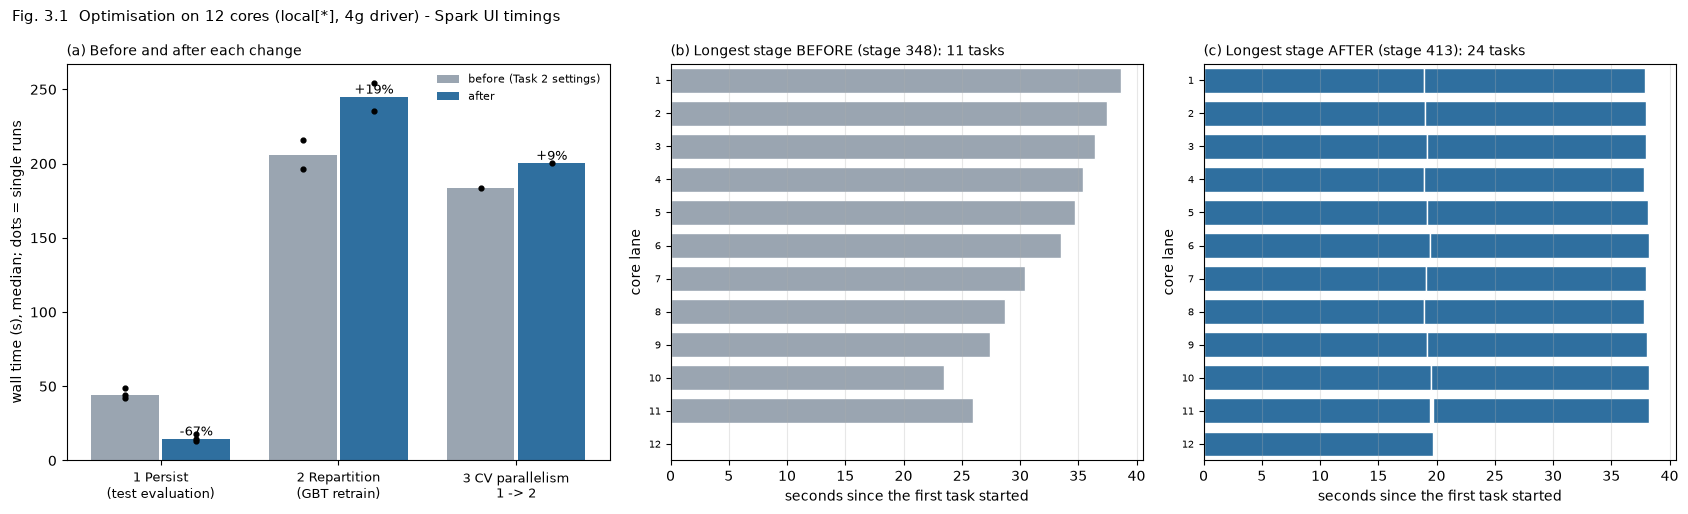

saved: task3/figures/task3_optimisation.png
saved: task3/results/task3_results.json [optimisation]
saved: results/task3.json [optimisation]


In [14]:
# ==============================================================================
# 3.1.6  Table 3.1, Fig. 3.1 and results/task3.json (optimisation section)
## AI: summary table, figure layout and JSON writer written with AI assistance
# ==============================================================================
import matplotlib.pyplot as plt


def pct_faster(c):
    return round(100 * (c["before_s"] - c["after_s"]) / c["before_s"], 1)


OPT_TABLE = pd.DataFrame([
    {"Change made": "Persist the scored test set",
     "Setting": "persist(MEMORY_AND_DISK), 4 columns",
     "Rationale": (f"{DIAG.get('full_scans', '?')} of {DIAG.get('jobs', '?')} metric jobs re-read {N_TEST:,} rows and "
                   f"re-ran the pipeline + {RECOMMENDED} (Table 3.1b); cache holds {STORAGE['four_columns_mb'][0]} MB "
                   f"vs {STORAGE['all_columns_mb'][0]} MB for all columns"),
     "Stage": f"test scan + score, repeated in {DIAG.get('full_scans', '?')} jobs",
     "Before (s)": round(C1["before_s"], 2), "After (s)": round(C1["after_s"], 2), "Faster (%)": pct_faster(C1)},
    {"Change made": "Repartition before caching",
     "Setting": f"{C2['partitions_before']} -> {TARGET_PARTITIONS} partitions (round-robin)",
     "Rationale": (f"{C2['partitions_before']} uneven partitions for {N_CORES} cores: longest task "
                   f"{P_B['max_over_median']}x the median on every pass; balanced tasks, 2 per core"),
     "Stage": (f"{est_cls.__name__} retrain, {P_B['pass_stages']} data passes of {P_B['tasks_per_pass']} -> "
               f"{P_A['tasks_per_pass']} tasks"),
     "Before (s)": round(C2["before_s"], 2), "After (s)": round(C2["after_s"], 2), "Faster (%)": pct_faster(C2)},
    {"Change made": "Fit CV combinations in parallel",
     "Setting": "CrossValidator parallelism 1 -> 2",
     "Rationale": (f"{C3['jobs']} short jobs left cores idle ({C3['core_use_before_pct']}% busy); 2 fits at a time "
                   f"-> {C3['core_use_after_pct']}% busy; 4 checked: {C3['checked_4_s']:.1f} s"),
     "Stage": f"CrossValidator.fit, LR 4 x {CV_FOLDS} folds on {N_TUNE:,} rows",
     "Before (s)": round(C3["before_s"], 2), "After (s)": round(C3["after_s"], 2), "Faster (%)": pct_faster(C3)},
])
show(OPT_TABLE, "Table 3.1  Spark UI interpretation and optimisation (median wall time, Task 2 settings as 'before')")
OPT_TABLE.to_csv(RES_DIR / "task3_optimisation.csv", index=False)

# ---- Fig. 3.1 ----
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.15, 1, 1]})
labels = ["1 Persist\n(test evaluation)", f"2 Repartition\n({est_cls.__name__[:3]} retrain)", "3 CV parallelism\n1 -> 2"]
runs = [(RUNS1["before"], RUNS1["after"]), (RUNS2["before"], RUNS2["after"]), ([C3["before_s"]], [C3["after_s"]])]
x = np.arange(3)
for i, (b, a) in enumerate(runs):
    ax1.bar(i - 0.2, statistics.median(b), 0.38, color="#9aa5b1", label="before (Task 2 settings)" if i == 0 else None)
    ax1.bar(i + 0.2, statistics.median(a), 0.38, color="#2f6f9f", label="after" if i == 0 else None)
    ax1.scatter([i - 0.2] * len(b), b, color="black", s=12, zorder=3)
    ax1.scatter([i + 0.2] * len(a), a, color="black", s=12, zorder=3)
    ax1.text(i + 0.2, statistics.median(a), f"{-OPT_TABLE.iloc[i]['Faster (%)']:+.0f}%", ha="center",
             va="bottom", fontsize=9)
ax1.set_xticks(x, labels, fontsize=9); ax1.set_ylabel("wall time (s), median; dots = single runs")
ax1.set_title("(a) Before and after each change", loc="left", fontsize=10); ax1.legend(fontsize=8, frameon=False)
for ax, key, title in ((ax2, "before", f"(b) Longest stage BEFORE (stage {STAGE_B}): {len(TL_B)} tasks"),
                       (ax3, "after", f"(c) Longest stage AFTER (stage {STAGE_A}): {len(TL_A)} tasks")):
    t = TIMELINE[key]
    lanes_end = []
    for _, r in t.iterrows():                                          # EXPLAIN: put each task on a free core lane
        lane = next((k for k, end in enumerate(lanes_end) if end <= r["start"] + 1e-3), None)
        if lane is None:
            lanes_end.append(0.0); lane = len(lanes_end) - 1
        lanes_end[lane] = r["start"] + r["dur"]
        ax.barh(lane, r["dur"], left=r["start"], height=0.75, color="#2f6f9f" if key == "after" else "#9aa5b1",
                edgecolor="white")
    ax.set_ylim(N_CORES - 0.5, -0.5); ax.set_yticks(range(N_CORES)); ax.set_yticklabels(range(1, N_CORES + 1), fontsize=7)
    ax.set_xlabel("seconds since the first task started"); ax.set_ylabel("core lane")
    ax.set_title(title, loc="left", fontsize=10)
xmax = max([(t["start"] + t["dur"]).max() for t in TIMELINE.values() if not t.empty] or [1])
for ax in (ax2, ax3):
    ax.set_xlim(0, xmax * 1.05); ax.grid(axis="x", alpha=0.3)
fig.suptitle(f"Fig. 3.1  Optimisation on {N_CORES} cores (local[*], {DRIVER_MEMORY} driver) - Spark UI timings",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "task3_optimisation.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved:", rel(FIG_DIR / "task3_optimisation.png"))


# ---- results/task3.json: written section by section (3.2 and 3.3 add their own blocks later) ----
def save_task3(section, payload):
    header = {"task": 3, "notebook": NOTEBOOK, "quick_test": QUICK_TEST, "student": task1.get("student"),
              "pool_reference": task1.get("pool_reference"), "problem_type": "regression", "target_col": TARGET,
              "input_contract": ["results/task1.json#handoff", "results/task2.json#models"],
              "executor_config": EXECUTOR_CONFIG, "resources": RESOURCES,
              "spark_ui": {"application_id": sc.applicationId, "url": sc.uiWebUrl, "rest_api_read": UI_REACHABLE}}
    targets = [RES_DIR / "task3_results.json"] + ([] if QUICK_TEST else [ROOT / "results" / "task3.json"])
    for path in targets:
        data = json.loads(path.read_text()) if path.exists() else {}
        if data and data.get("notebook") != NOTEBOOK:
            print(f"NOT overwritten: {rel(path)} was written by another notebook"); continue
        data.update(header); data[section] = payload
        path.write_text(json.dumps(data, indent=2, default=str))
        print("saved:", rel(path), f"[{section}]")


save_task3("optimisation", {
    "method": "Task 2 settings as 'before'; one change at a time; before/after runs alternate; median wall time; "
              "every run is a named Spark job group; stage metrics read from the Spark UI REST API",
    "recommended_model": RECOMMENDED, "input_layout": INPUT_LAYOUT.to_dict("records"),
    "baseline": {"diagnosis": DIAG, "jobs": BASE_JOBS.to_dict("records"), "stages": BASE_STAGES.to_dict("records")},
    "changes": OPT_TABLE.to_dict("records"),
    "details": {"persist": C1, "repartition": C2, "cv_parallelism": C3},
    "measured_at": time.strftime("%Y-%m-%d %H:%M:%S"),
})